# Part 1: Import Required Libraries(DONE)

In [ ]:
import kagglehub
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import tensorflow as tf
import warnings
warnings.filterwarnings('ignore')
from tensorflow.keras import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense,Flatten,MaxPooling2D,Conv2D,Dropout,BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

# Part 2: Define Dataset Paths(DONE)

In [3]:
trainp='/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/train'
valp='/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/validation'
testp='/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test'

# Part 3: Count Images in Each Class(DONE)

In [4]:
classes=os.listdir(trainp)
classes

['Bean',
 'Bitter_Gourd',
 'Bottle_Gourd',
 'Brinjal',
 'Broccoli',
 'Cabbage',
 'Capsicum',
 'Carrot',
 'Cauliflower',
 'Cucumber',
 'Papaya',
 'Potato',
 'Pumpkin',
 'Radish',
 'Tomato']

In [5]:
images=trainp+'/'+classes[0]
len(os.listdir(images))

1000

In [6]:
def count_class(data_path):
    dic={}
    sum=0
    for typ in classes:
        type_path=data_path+'/'+typ
        dic[typ]=len(os.listdir(type_path))
        
        sum+=len(os.listdir(type_path))
    #dic['sum of all classes']=sum
    return dic
count_class(trainp)

{'Bean': 1000,
 'Bitter_Gourd': 1000,
 'Bottle_Gourd': 1000,
 'Brinjal': 1000,
 'Broccoli': 1000,
 'Cabbage': 1000,
 'Capsicum': 1000,
 'Carrot': 1000,
 'Cauliflower': 1000,
 'Cucumber': 1000,
 'Papaya': 1000,
 'Potato': 1000,
 'Pumpkin': 1000,
 'Radish': 1000,
 'Tomato': 1000}

In [7]:
count_class(valp)

{'Bean': 200,
 'Bitter_Gourd': 200,
 'Bottle_Gourd': 200,
 'Brinjal': 200,
 'Broccoli': 200,
 'Cabbage': 200,
 'Capsicum': 200,
 'Carrot': 200,
 'Cauliflower': 200,
 'Cucumber': 200,
 'Papaya': 200,
 'Potato': 200,
 'Pumpkin': 200,
 'Radish': 200,
 'Tomato': 200}

In [8]:
count_class(testp)

{'Bean': 200,
 'Bitter_Gourd': 200,
 'Bottle_Gourd': 200,
 'Brinjal': 200,
 'Broccoli': 200,
 'Cabbage': 200,
 'Capsicum': 200,
 'Carrot': 200,
 'Cauliflower': 200,
 'Cucumber': 200,
 'Papaya': 200,
 'Potato': 200,
 'Pumpkin': 200,
 'Radish': 200,
 'Tomato': 200}

# Part 4: Create a Summary DataFrame(DONE)

In [9]:
train_dic=count_class(trainp)
val_dic=count_class(valp)
test_dic=count_class(testp)

In [10]:
merged=pd.DataFrame({'Vegtables':classes})
merged

,Vegtables
0,Bean
1,Bitter_Gourd
2,Bottle_Gourd
3,Brinjal
4,Broccoli
5,Cabbage
6,Capsicum
7,Carrot
8,Cauliflower
9,Cucumber


In [11]:
train_df=pd.DataFrame(train_dic,index=range(len(classes))).iloc[:,0]
val_df=pd.DataFrame(val_dic,index=range(len(classes))).iloc[:,0]
test_df=pd.DataFrame(test_dic,index=range(len(classes))).iloc[:,0]

In [12]:
merged['Train Count']=train_df
merged['Validation Count']=val_df
merged['Test Count']=test_df
merged

,Vegtables,Train Count,Validation Count,Test Count
0,Bean,1000,200,200
1,Bitter_Gourd,1000,200,200
2,Bottle_Gourd,1000,200,200
3,Brinjal,1000,200,200
4,Broccoli,1000,200,200
5,Cabbage,1000,200,200
6,Capsicum,1000,200,200
7,Carrot,1000,200,200
8,Cauliflower,1000,200,200
9,Cucumber,1000,200,200


### The classes are perfectly balanced.

# Part 5: Visualize Class Distribution(DONE)

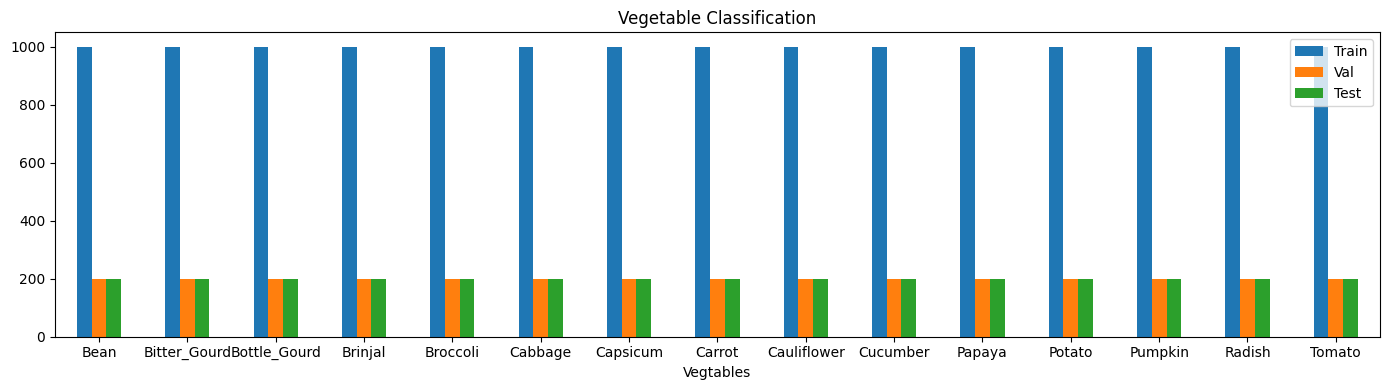

In [13]:
merged.set_index('Vegtables').plot(kind='bar',figsize=(14,4))
plt.xticks(rotation=0)
plt.title('Vegetable Classification')
plt.legend(['Train','Val','Test'])
plt.tight_layout()
plt.show()

- Yes, the data is balanced, every vegetable has the same amount of train,validation and test data as the others.

# Part 6: Image Preprocessing and Augmentation(DONE)

In [14]:
train_generator=ImageDataGenerator(
    rescale=1/255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.1,
    shear_range=0.2,
    zoom_range=0.4,
    horizontal_flip=True,
    validation_split=0.2
)

val_generator=ImageDataGenerator(
    rescale=1/255,
    validation_split=0.2
)

'''test_generator=ImageDataGenerator(
    rescale=1/255
)'''

'test_generator=ImageDataGenerator(\n    rescale=1/255\n)'

# Part 7: Load Images Using flow_from_directory(DONE)

In [15]:
train_ds=train_generator.flow_from_directory(
    trainp,
    target_size = (224, 224),
    batch_size = 32,
    class_mode = "categorical",
    seed = 42,
    subset = 'training'
)

val_ds=val_generator.flow_from_directory(
    trainp,
    target_size = (224, 224),
    batch_size = 32,
    class_mode = "categorical",
    seed = 42,
    subset = 'validation'
)



'''test=test_generator.flow_from_directory(
    testp,
    target_size=(224,224),
    class_mode = "categorical",
    seed = 42,
    shuffle=False
)'''

Found 12000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.


'test=test_generator.flow_from_directory(\n    testp,\n    target_size=(224,224),\n    class_mode = "categorical",\n    seed = 42,\n    shuffle=False\n)'

# Part 8: Build the CNN Model(DONE)

In [16]:
cnn=Sequential([
    
    Conv2D(filters=32,kernel_size=(3,3),activation='relu',input_shape=(224,224,3),padding='same'),
    MaxPooling2D(pool_size=(2,2)),

    Conv2D(filters=64,kernel_size=(3,3),activation=('relu'),padding='same'),
    MaxPooling2D(pool_size=(2,2)),

    Conv2D(filters=128,kernel_size=(3,3),activation='relu',padding='same'),
    MaxPooling2D(pool_size=(2,2)),

    Flatten(),
    Dense(512,activation='relu'),
    Dropout(0.5),
    Dense(15,activation='softmax')
    
])

I0000 00:00:1793561991.591438      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793561991.594879      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


# Part 9: Compile the Model(DONE)

In [17]:
cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    51,380,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,481,679 (196.39 MB)

 Trainable params: 51,481,679 (196.39 MB)

 Non-trainable params: 0 (0.00 B)

- We have 3 convolutional layers.
- Pooling layers
- Dropout layer turn off some of the neurons to prevent overfitting and make the model more robust.
- Softmax is used because our task is mult-class classification.

# Part 10: Train the Model(DONE)

In [18]:
early=EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True)
history=cnn.fit(train_ds,validation_data=val_ds,epochs=20,callbacks=early)


Epoch 1/20
  2/375 ━━━━━━━━━━━━━━━━━━━━ 21s 58ms/step - accuracy: 0.0547 - loss: 3.7460   

I0000 00:00:1793562007.470151      86 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


375/375 ━━━━━━━━━━━━━━━━━━━━ 807s 2s/step - accuracy: 0.4408 - loss: 1.6503 - val_accuracy: 0.7323 - val_loss: 0.8025
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 152s 406ms/step - accuracy: 0.6714 - loss: 0.9942 - val_accuracy: 0.8103 - val_loss: 0.5586
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 154s 411ms/step - accuracy: 0.7701 - loss: 0.7141 - val_accuracy: 0.8817 - val_loss: 0.3374
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 147s 393ms/step - accuracy: 0.8140 - loss: 0.5779 - val_accuracy: 0.8907 - val_loss: 0.3049
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 148s 393ms/step - accuracy: 0.8279 - loss: 0.5219 - val_accuracy: 0.9313 - val_loss: 0.2285
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 149s 396ms/step - accuracy: 0.8467 - loss: 0.4723 - val_accuracy: 0.9363 - val_loss: 0.1991
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 148s 394ms/step - accuracy: 0.8740 - loss: 0.3947 - val_accuracy: 0.9380 - val_loss: 0.1902
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 149s 397ms/step - accuracy: 0.8743 - loss: 0.3917 

- EarlyStopping is very useful in detecting if the model has converged respect to the metrics we chose.

# Part 11: Evaluate the Model(DONE)

In [19]:
cnn.evaluate(train_ds)

375/375 ━━━━━━━━━━━━━━━━━━━━ 139s 371ms/step - accuracy: 0.9718 - loss: 0.0950


[0.0949685126543045, 0.971750020980835]

In [20]:
cnn.evaluate(val_ds)

94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - accuracy: 0.9783 - loss: 0.0683


[0.06833313405513763, 0.9783333539962769]

- No ,there isn't a big difference between train and validation so the model doesn't overfit. 

# Part 12: Plot Accuracy and Loss Curves

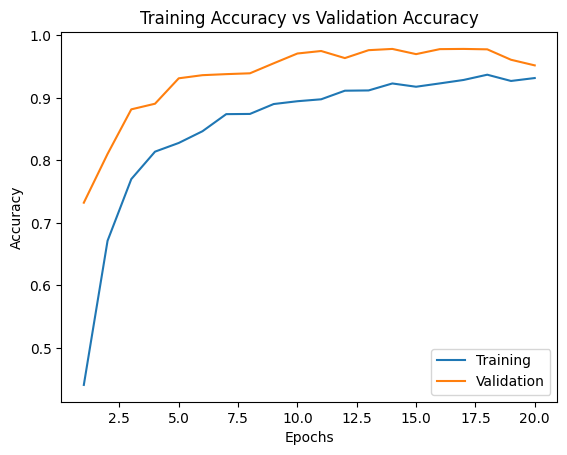

In [21]:
sns.lineplot(y=history.history["accuracy"],x=(range(1,len(history.history['accuracy'])+1)),label='Training')
sns.lineplot(y=history.history["val_accuracy"],x=(range(1,len(history.history['val_accuracy'])+1)),label='Validation')
plt.title('Training Accuracy vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

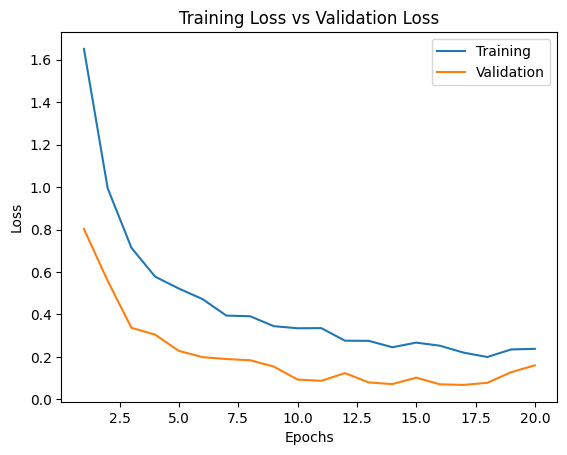

In [22]:
sns.lineplot(x=range(1,len(history.history['loss'])+1),y=history.history['loss'],label='Training')
sns.lineplot(x=range(1,len(history.history['loss'])+1),y=history.history['val_loss'],label='Validation')
plt.title('Training Loss vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()